# Application 1: a small VQE for H2

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/applications/01_vqe_h2.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/applications/01_vqe_h2.ipynb)

A variational eigensolver prepares a trial state with a parameterized circuit and minimises its energy. For H2 (STO-3G, Jordan-Wigner, bond length 0.7414 A) the qubit Hamiltonian is 15 Pauli strings on 4 qubits. Here the energy of the ansatz is reconstructed from cut circuits on at most 2 qubits, and a classical optimiser runs on that.

This is an exercise in the workflow, not a result about chemistry: 4 qubits need no cutting. It combines **a Hamiltonian** (notebook 05), **free parameters** (notebook 12) and **error bars** (notebook 11). It runs serially; under PyCOMPSs the same code runs its circuits as tasks (notebook 09).

In [1]:
# Installs Qdislib on Colab or Binder; does nothing where Qdislib 2 is installed.
try:
    import Qdislib
    assert Qdislib.__version__.startswith("2.")
except (ImportError, AssertionError):
    %pip install -q "qdislib[qiskit]>=2.0"

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from scipy.optimize import minimize
import Qdislib as qd

# Coefficients from a standard quantum-chemistry calculation; q0 is the first character.
HAMILTONIAN = [
    (-0.04207897, "IIII"),
    (0.17771287, "ZIII"), (0.17771287, "IZII"),
    (-0.24274281, "IIZI"), (-0.24274281, "IIIZ"),
    (0.17059738, "ZZII"),
    (0.12293305, "ZIZI"), (0.16768319, "ZIIZ"),
    (0.16768319, "IZZI"), (0.12293305, "IZIZ"),
    (0.17627641, "IIZZ"),
    (0.04475014, "YXXY"), (-0.04475014, "YYXX"),
    (-0.04475014, "XXYY"), (0.04475014, "XYYX"),
]

## The ansatz

The ground state lies in the two-configuration space of `|1100>` and `|0011>`. One parameter interpolates between them, which is enough to reach it.

In [3]:
theta = Parameter("theta")
ansatz = QuantumCircuit(4)
ansatz.ry(theta, 0)
ansatz.cx(0, 1)
ansatz.x(2)
ansatz.x(3)
ansatz.cx(0, 2)
ansatz.cx(0, 3)
print(ansatz.draw(fold=80))

     ┌───────────┐               
q_0: ┤ Ry(theta) ├──■────■────■──
     └───────────┘┌─┴─┐  │    │  
q_1: ─────────────┤ X ├──┼────┼──
         ┌───┐    └───┘┌─┴─┐  │  
q_2: ────┤ X ├─────────┤ X ├──┼──
         ├───┤         └───┘┌─┴─┐
q_3: ────┤ X ├──────────────┤ X ├
         └───┘              └───┘


## The cut

`find_cut` works on the circuit with its symbolic angle. Two CX cuts leave fragments of at most 2 qubits. Grouping the terms (notebook 05) means far fewer circuits than one set per term.

['CX_2', 'CX_5'] {'subcircuits': 108, 'configurations': 36, 'fragments': 3, 'gamma': 9.0}
540 circuits for the Hamiltonian; term by term it would be 1512


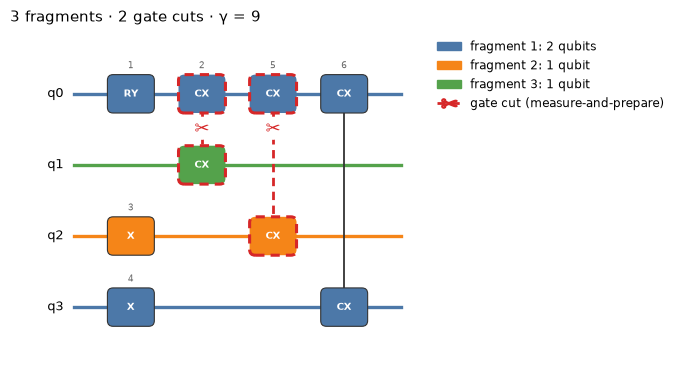

In [4]:
cut = qd.find_cut(ansatz, max_qubits=2, wire_cut=False)
cost = qd.cutting_overhead(ansatz, cut)
print(cut, cost)

circuits = len(qd.circuit_cutting_subcircuits(ansatz, cut, HAMILTONIAN))
print(f"{circuits} circuits for the Hamiltonian; term by term it would be {14 * cost['subcircuits']}")
qd.draw_cut(ansatz, cut);

## The energy landscape

`parameter_values=` runs the same cut for many angles. `shots=None` is exact, which gives the reference curve. The points are runs with shots, with their standard errors; each one is `shots` per circuit, so several hundred thousand shots per point.

lowest on the grid: -1.1362 Ha at theta = 3.351


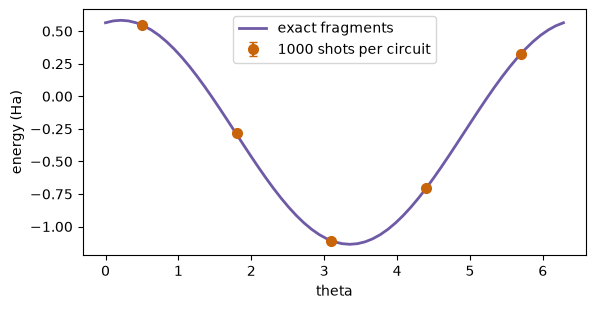

In [5]:
angles = np.linspace(0, 2 * np.pi, 61)
exact = qd.circuit_cutting(ansatz, cut, HAMILTONIAN, shots=None, parameter_values=[[float(a)] for a in angles])
print(f"lowest on the grid: {min(exact):.4f} Ha at theta = {angles[int(np.argmin(exact))]:.3f}")

points = np.linspace(0.5, 5.7, 5)
measured = qd.circuit_cutting(ansatz, cut, HAMILTONIAN, shots=1000, seed=1, error=50,
                              parameter_values=[[float(a)] for a in points])

plt.figure(figsize=(6.5, 3.2))
plt.plot(angles, exact, color="#6f5aa6", linewidth=2, label="exact fragments")
plt.errorbar(points, [float(m) for m in measured], yerr=[m.error for m in measured],
             fmt="o", markersize=7, color="#c8640a", capsize=3, label="1000 shots per circuit")
plt.xlabel("theta")
plt.ylabel("energy (Ha)")
plt.legend()
plt.show()

## Minimising the energy

An optimiser drives the cut through `parameter_values`, always on the same plan. It runs on the exact fragments so that it finishes quickly; with `shots=` it would be the same code.

In [6]:
def energy(values):
    return qd.circuit_cutting(ansatz, cut, HAMILTONIAN, shots=None, parameter_values=[list(values)])[0]


result = minimize(energy, x0=[2.5], method="COBYLA", options={"maxiter": 30, "rhobeg": 0.5})
print(f"{result.nfev} evaluations: E = {result.fun:.5f} Ha at theta = {result.x[0]:.4f}")

21 evaluations: E = -1.13619 Ha at theta = 3.3514


Then a final estimate of that point, with shots and a standard error.

In [7]:
final = qd.circuit_cutting(ansatz, cut, HAMILTONIAN, shots=4000, seed=2, error=50,
                           parameter_values=[[float(result.x[0])]])[0]
print(f"with shots: {final} Ha;  exact fragments: {result.fun:.5f} Ha")
print(f"total shots of this estimate: {final.shots}")

with shots: -1.13661 ± 0.0023 Ha;  exact fragments: -1.13619 Ha
total shots of this estimate: 2160000


The value is the minimum of this Hamiltonian's energy on this ansatz. A standard error of a few mHa here takes well over a million shots, which is the combination of 15 terms and `gamma = 9`. That cost, and not the 4 qubits, is the thing to watch when moving to larger molecules: see **application 2**.